In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

df = pd.read_csv("/content/data/Used_Car_Dataset.csv")

print(df.head())

   Year  Mileage_km  Engine_Size_cc  Num_Owners  Fuel_Efficiency_kmpl  \
0  2014      127989            3062           3             16.249345   
1  2017      281393            4029           2             17.237899   
2  2001      249255            2916           3             13.180936   
3  2009      115361            1192           4             11.090744   
4  2022      291744            1908           4              9.460477   

      Price_INR  
0  1.636551e+06  
1  2.206040e+06  
2  2.615662e+05  
3  1.660000e+05  
4  1.660000e+05  


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1000, 6)

Column names:
Index(['Year', 'Mileage_km', 'Engine_Size_cc', 'Num_Owners',
       'Fuel_Efficiency_kmpl', 'Price_INR'],
      dtype='object')

Missing values:
Year                    0
Mileage_km              0
Engine_Size_cc          0
Num_Owners              0
Fuel_Efficiency_kmpl    0
Price_INR               0
dtype: int64


In [ ]:
df = df[["Engine_Size_cc", "Price_INR"]]

df = df.dropna()

df = df.drop_duplicates()

print("Dataset after cleaning:")
print(df.head())

print("\nShape after cleaning:", df.shape)

Dataset after cleaning:
   Engine_Size_cc     Price_INR
0            3062  1.636551e+06
1            4029  2.206040e+06
2            2916  2.615662e+05
3            1192  1.660000e+05
4            1908  1.660000e+05

Shape after cleaning: (988, 2)


In [ ]:
X = df[["Engine_Size_cc"]]

y = df["Price_INR"]

print("X:")
print(X.head())

print("\nY:")
print(y.head())

X:
   Engine_Size_cc
0            3062
1            4029
2            2916
3            1192
4            1908

Y:
0    1.636551e+06
1    2.206040e+06
2    2.615662e+05
3    1.660000e+05
4    1.660000e+05
Name: Price_INR, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (691, 1)
Testing data: (297, 1)


In [ ]:
model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predicted prices:")
print(y_pred[:10])

Predicted prices:
[1730657.98489316 1399215.5714629  1494115.74966729 1158424.07452639
 1285193.71556062 2650623.14524764 1597514.45129297 2596090.95329438
 1914792.65902108 1136469.55568807]


In [ ]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)

Mean Squared Error (MSE): 195369371579.53125


In [ ]:
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(results.head(10))

   Actual Price  Predicted Price
0  5.433562e+05     1.730658e+06
1  1.982886e+06     1.399216e+06
2  1.686496e+06     1.494116e+06
3  1.152794e+06     1.158424e+06
4  1.350653e+06     1.285194e+06
5  2.705262e+06     2.650623e+06
6  1.964110e+06     1.597514e+06
7  2.784593e+06     2.596091e+06
8  2.192463e+06     1.914793e+06
9  1.074223e+06     1.136470e+06


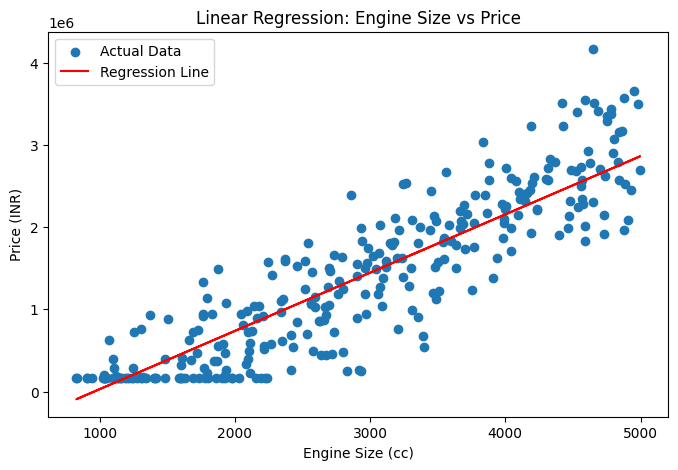

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, label="Actual Data")

plt.plot(X_test, y_pred, color="red", label="Regression Line")

plt.xlabel("Engine Size (cc)")
plt.ylabel("Price (INR)")
plt.title("Linear Regression: Engine Size vs Price")

plt.legend()
plt.show()

In [ ]:
print("Slope (Coefficient):", model.coef_[0])
print("Intercept:", model.intercept_)

print(
    "Regression Equation: Price_INR =",
    model.intercept_,
    "+",
    model.coef_[0],
    "* Engine_Size_cc"
)

Slope (Coefficient): 708.2102851073798
Intercept: -678673.4050421489
Regression Equation: Price_INR = -678673.4050421489 + 708.2102851073798 * Engine_Size_cc
